# Libreta de Exploración de datos crudos de página MiBici

Propósito: leer los datos tal como están en MiBici, y ver dónde es necesario hacer ajustes para homologar los datos en un solo dataframe.

In [17]:
from pathlib import Path
import re
import time
from urllib.parse import urljoin
import pandas as pd
import matplotlib.pyplot as plt

import requests
from tqdm import tqdm
from datetime import date

In [4]:
# Fuente de los datos
URL_PORTAL = "https://mibici.net/es/datos-abiertos/"
ENCABEZADOS_HTTP = {
    "User-Agent": "Mozilla/5.0 (proyecto academico MLOps TC5061)",
    "Accept": "text/html,text/csv,*/*",
}

RUTA_VIAJES_CRUDOS = Path("../data/raw")
RUTA_ESTACIONES_CRUDAS = Path("../data/raw/estaciones")
MES_INICIO = "2020-01"
MES_FIN = str(pd.Timestamp.today().to_period("M") - 1)  # hasta el mes anterior al actual, igual que leer_datos_anuales

In [ ]:
def descargar_csv_crudos(mes_inicio = MES_INICIO, mes_fin = MES_FIN):
    
    portal = requests.get(URL_PORTAL, headers=ENCABEZADOS_HTTP, timeout=30)
    portal.raise_for_status()

    # Las URLs se leen de la página: cada archivo vive en una carpeta con un identificador distinto
    patron = r"(?P<archivo>(?P<tipo>datos_abiertos|nomenclatura)_(?P<anio>\d{4})_(?P<mes>\d{2})\.csv)"
    viajes, nomenclaturas = {}, {}
    for href in re.findall(r"href=['\"]([^'\"]+)['\"]", portal.text):
        coincidencia = re.search(patron, href)
        if coincidencia:
            periodo = f"{coincidencia['anio']}-{coincidencia['mes']}"
            destino = viajes if coincidencia["tipo"] == "datos_abiertos" else nomenclaturas
            destino[coincidencia["archivo"]] = (periodo, urljoin(URL_PORTAL, href))

    meses = set(pd.period_range(mes_inicio, mes_fin, freq="M").astype(str))
    pendientes = [
        (RUTA_VIAJES_CRUDOS / archivo, url)
        for archivo, (periodo, url) in viajes.items()
        if periodo in meses
    ]
    sin_publicar = sorted(meses - {periodo for periodo, _ in viajes.values()})
    if nomenclaturas:
        archivo, (_, url) = max(nomenclaturas.items(), key=lambda item: item[1][0])
        pendientes.append((RUTA_ESTACIONES_CRUDAS / archivo, url))

    rutas = []
    for destino, url in tqdm(pendientes, desc="Descarga"):
        destino.parent.mkdir(parents=True, exist_ok=True)
        if not destino.exists():
            respuesta = requests.get(url, headers=ENCABEZADOS_HTTP, timeout=60)
            respuesta.raise_for_status()
            temporal = destino.with_suffix(".part")
            temporal.write_bytes(respuesta.content)  # bytes sin decodificar
            temporal.replace(destino)
            time.sleep(1)  # pausa para no saturar el portal
        rutas.append(destino)
    return rutas

In [6]:
rutas = descargar_csv_crudos(MES_INICIO, MES_FIN)

Descarga: 100%|██████████| 82/82 [06:11<00:00,  4.53s/it]


In [7]:
def conversion_a_datetime(str_col):
    try:
        # ISO8061: %Y-%m-%d %H:%M
        dt_col = pd.to_datetime(str_col, format="ISO8601")
    except ValueError:
        # Archivos encontrados con formato no ISO8601:
        # Año 2023 mes 11
        # Año 2024 mes 09
        # Año 2024 mes 10
        dt_col = pd.to_datetime(str_col, format="%d/%m/%Y %H:%M")
    
    return dt_col

In [8]:
def leer_datos_mensuales(direccion, convencion, ano, mes):
    data_file_name = f"{convencion}_{ano}_{mes:02}.csv"
    filepath = f"{direccion}/{data_file_name}"

    # Leer archivos ya sea con utf-8 o latin-1 en caso de error
    try:
        df = pd.read_csv(filepath, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(filepath, encoding="latin-1")
    
    # Archivo de año 2023, mes 04 encontrado con nombre incorrecto
    if "A}äe_nacimiento" in df:
        df = df.rename(columns={"A}äe_nacimiento": "Año_de_nacimiento"})

    # Por auditoría, guardar el nombre del archivo
    df["Archivo_de_origen"] = filepath
    
    # Convertir inicio y fin de viaje a datetime
    df["Inicio_del_viaje"] = conversion_a_datetime(df["Inicio_del_viaje"])
    df["Fin_del_viaje"] = conversion_a_datetime(df["Fin_del_viaje"])
        
    return df

In [9]:
def leer_datos_anuales(direccion, convencion, ano):
    # Obtener mes máximo a consultar (12 para años anteriores, mes actual - 1 para año actual)
    today = date.today()
    mes_max = today.month - 1 if int(ano) == today.year else 12

    # Inicializar dataframe de salida con la primera lectura de archivo
    resultado = leer_datos_mensuales(direccion, convencion, ano, 1)

    if mes_max == 1:
        return resultado
    else:
        # Concatenar los otros archivos del año en un solo dataframe
        for mes in range(2, mes_max+1):
            # Se leen los archivos para cada mes
            df_a_concatenar = leer_datos_mensuales(direccion, convencion, ano, mes)

            # Se revisa si el esquema del archivo leido es igual al de los ya leidos
            try:
                pd.testing.assert_series_equal(resultado.dtypes, df_a_concatenar.dtypes)
            except AssertionError:
                print(f"Diferencia en esquema encontrada entre archivos:")
                print(f"{convencion}_{ano}_{mes:02}.csv")
                print(f"{convencion}_{ano}_{(mes-1):02}.csv")
                raise

            # Se concatena el dataframe del archivo leido al dataframe de salida
            resultado = pd.concat([resultado, df_a_concatenar])
            
    # Se resetea el índice del dataframe de salida
    resultado = resultado.reset_index(drop=True)
    
    return resultado


In [10]:
def leer_multiples_datos_anuales(direccion, convencion, ano_min, ano_max):

    resultado = leer_datos_anuales(direccion, convencion, ano_min)

    if ano_min == ano_max:
        return resultado
    else:
        for ano in range(ano_min+1, ano_max+1):
            df_a_concatenar = leer_datos_anuales(direccion, convencion, ano)
            
            try:
                pd.testing.assert_series_equal(resultado.dtypes, df_a_concatenar.dtypes)
            except AssertionError:
                print(f"Diferencia en esquema encontrada entre años {ano-1} y {ano}")
                raise
            
            resultado = pd.concat([resultado, df_a_concatenar])
        
    resultado = resultado.reset_index(drop=True)
    
    return resultado

In [13]:
convencion="datos_abiertos"

# Se lee todo del 2020 a 2026
df = leer_multiples_datos_anuales(RUTA_VIAJES_CRUDOS, convencion, 2020, 2026)

In [14]:
def redondear_a_primer_dia_del_mes(dt_col):
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

In [15]:
df["Mes_redondeado"] = redondear_a_primer_dia_del_mes(df["Inicio_del_viaje"])

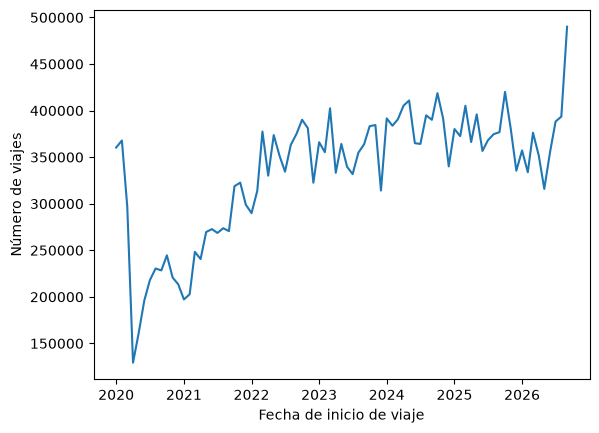

In [18]:
groupedby = df.groupby(df["Mes_redondeado"])['Viaje_Id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

Esta gráfica es muy similar a la que MiBici despliega en su página. Por ende, este dataframe se considera propiamente homologado para propósitos de un análisis de estaciones (problema P2).